# Como rodar

```bash
docker compose build
```
```bash
sudo docker compose run --rm --service-ports notebook \
  jupyter lab --ip=0.0.0.0 --port=8888 --no-browser --allow-root
  ```

### Importando as dependências

Experimentos de retomada de sessões pós-quânticas em IoT sob falhas de estado.


In [1]:
%matplotlib inline
from pqc_iot_simulator import Network, Logger
from pqc_iot_simulator.pqc_iot_sim.crypto.tls.diagnostics import TicketDiagnostics
from IPython.display import display
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import json

plt.ioff()
cores = ["#315a91", "#b56a29", "#227a65"]
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9,
                     "xtick.labelsize": 7.3, "ytick.labelsize": 8.5,
                     "axes.titlesize": 9, "legend.fontsize": 7.3,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "pdf.fonttype": 42, "svg.fonttype": "none"})


### Instanciando a rede, configurando a topologia e ativando o log

Usamos uma estrela com um sensor (`iot_1`), um ponto de acesso (`gateway_1`) e um servidor TLS (`server_1`). O sensor se conecta ao ponto de acesso por Wi-Fi, e o ponto de acesso se conecta ao servidor por Ethernet virtual.

A chamada `start()` inicia uma campanha e apaga os resultados anteriores em `results/retomada`.


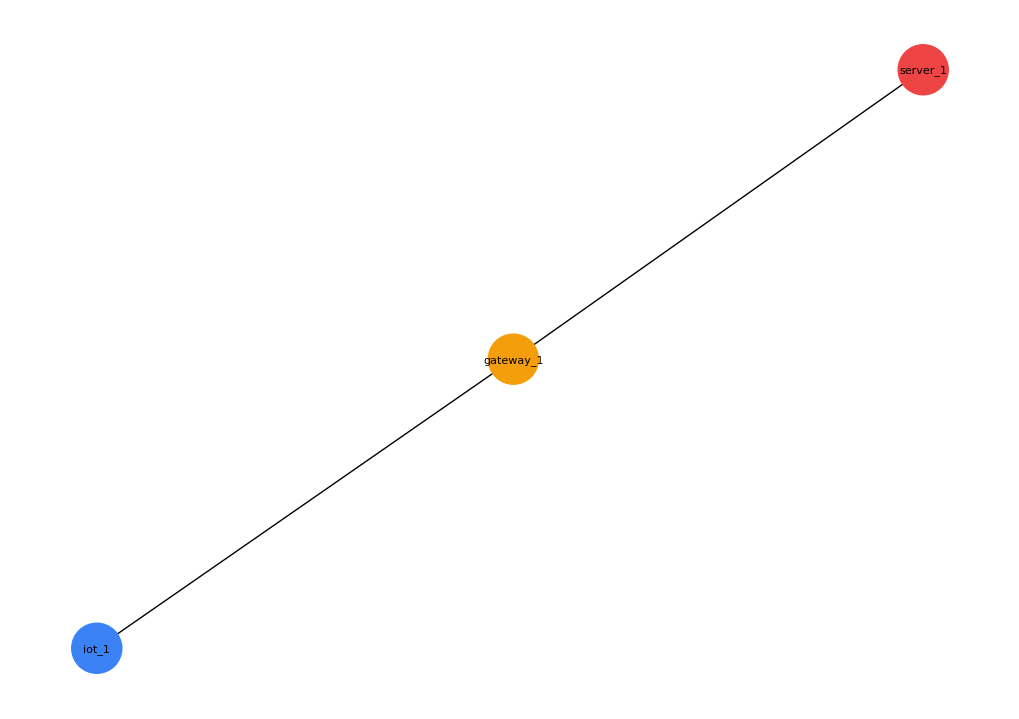

17:33:19 | Logger ativado


PosixPath('/workspace/results/retomada/20261112T173322564183Z')

In [2]:
rede = Network()
rede.set_ready_topology("Star", 1)
rede.draw()
Logger.activate()
rede.recovery.start()


### Configurações dos experimentos

Usamos TLS 1.3 com autenticação mútua, AES-256-GCM/SHA-384 e 0-RTT desabilitado.

| Perfil | Troca de chaves | Autenticação |
|---|---|---|
| Clássico | X25519 | ECDSA P-256 |
| Híbrido | X25519MLKEM768 | ECDSA P-256 |
| Pós-quântico | X25519MLKEM768 | ML-DSA-44 |

Comparamos autenticação completa, contexto perdido e contexto preservado, em dez blocos. O atraso configurado é de 2 ms por direção. Os reinícios interrompem o processo servidor TLS em `server_1`, mantendo o ponto de acesso ativo.


### Executando as falhas de estado e as interrupções do protótipo

Usamos oito mensagens e reserva de 32 contadores. São 240 execuções de falhas de estado e 330 de interrupções.


In [3]:
rede.recovery.run_prototype(repetitions=10, messages=8, block_size=32)


liboqs-python faulthandler is disabled
{"completed_repetitions": 1, "cases": 24}
{"completed_repetitions": 2, "cases": 48}
{"completed_repetitions": 3, "cases": 72}
{"completed_repetitions": 4, "cases": 96}
{"completed_repetitions": 5, "cases": 120}
{"completed_repetitions": 6, "cases": 144}
{"completed_repetitions": 7, "cases": 168}
{"completed_repetitions": 8, "cases": 192}
{"completed_repetitions": 9, "cases": 216}
{"completed_repetitions": 10, "cases": 240}
{
  "output": "/workspace/results/retomada/20261112T173322564183Z/prototype",
  "status": "SUPPORTED_IN_TESTED_MODEL",
  "criteria": {
    "negative_control_recovers_plaintext": true,
    "renewed_keys_no_nonce_reuse_all_delivered": true,
    "durable_counter_survives_power_loss": true,
    "durable_counter_not_rollback_proof": true,
    "security_gates": true,
    "pqc_resume_smaller_than_full": true
  },
  "median_resume_byte_reduction_pct": 66.14487746950233,
  "publication_novelty": "NOT_ESTABLISHED",
  "scope": "client roll

{'security': '/workspace/results/retomada/20261112T173322564183Z/prototype',
 'transitions': '/workspace/results/retomada/20261112T173322564183Z/transitions'}

### Figura 4 — Falhas de estado e reserva de contadores

Lemos os resultados do protótipo e desenhamos os quatro painéis. Reutilizações e textos recuperados são totais; escritas representam a mediana por execução.


In [4]:
estados = pd.DataFrame(json.loads((rede.recovery.directory / "prototype/results.json").read_text())["cases"])
politicas_estado = ["checkpoint", "persist_each", "reserve_blocks", "full_pqc", "psk_resume", "pqc_resume"]
nomes_estado = ["Checkpoint", "Por uso", "Blocos", "Completo", "PSK", "PSK+KEM"]
fig4, eixos4 = plt.subplots(2, 2, figsize=(9.2, 6.8), layout="constrained")
paineis_estado = [
    ("power_loss", "reused_key_nonce", "sum", "(a) Queda de energia modelada.", "Reutilizações de chave e nonce"),
    ("client_storage_rollback", "reused_key_nonce", "sum", "(b) Rollback do armazenamento.", "Reutilizações de chave e nonce"),
    ("client_storage_rollback", "known_plaintext_recoveries", "sum", "(c) Textos recuperados.", "Textos recuperados"),
    ("power_loss", "steady_state_writes", "median", "(d) Escritas na fase estável.", "Escritas por execução"),
]
for ax, (falha, campo, agregacao, titulo, unidade) in zip(eixos4.flat, paineis_estado):
    valores = estados.query("fault == @falha").groupby("policy")[campo].agg(agregacao).reindex(politicas_estado)
    barras = ax.bar(nomes_estado, valores, color=cores[0])
    ax.bar_label(barras, fmt="%g", padding=3)
    ax.set(title=titulo, ylabel=unidade, ylim=(0, max(valores.max() * 1.23, 1)))
    ax.tick_params(axis="x", labelrotation=30)
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)


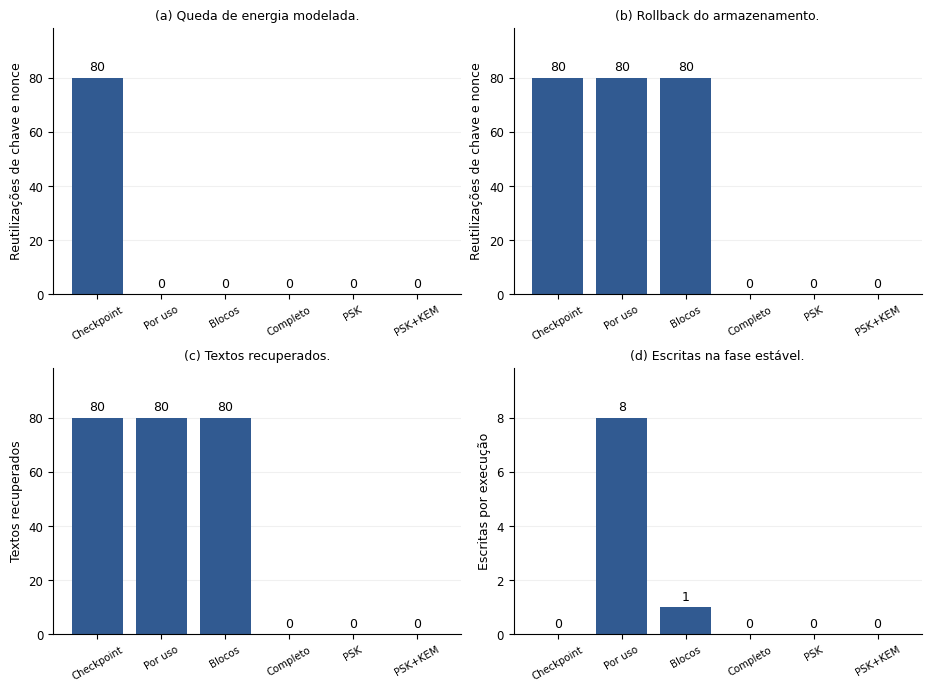

In [5]:
pasta_prototipo = rede.recovery.directory / "prototype_figures"
pasta_prototipo.mkdir(parents=True, exist_ok=True)
for formato in ("png", "pdf", "svg"):
    fig4.savefig(pasta_prototipo / f"figura_4_estado.{formato}", dpi=300)
display(fig4)
plt.close(fig4);


### Figura 5 — Interrupções do protótipo

Os pontos A–K seguem a ordem das falhas registradas. Calculamos as medianas dos bytes, os totais de fallbacks e os efeitos duplicados após confirmação perdida.


In [6]:
interrupcoes = pd.DataFrame(json.loads((rede.recovery.directory / "transitions/results.json").read_text())["cases"])
modos_prototipo = ["full_pqc", "psk_resume", "pqc_resume"]
cenarios = interrupcoes["scenario"].drop_duplicates().tolist()
bytes_interrupcao = interrupcoes.pivot_table(index="scenario", columns="policy", values="total_handshake_bytes", aggfunc="median").reindex(cenarios)
fig5, eixos5 = plt.subplots(2, 2, figsize=(9.2, 6.8), layout="constrained")

# (a) Bytes enquadrados por ponto de interrupção.
for modo, nome, cor in zip(modos_prototipo, ["Completo", "PSK", "PSK+KEM"], cores):
    eixos5[0, 0].plot(list("ABCDEFGHIJK"), bytes_interrupcao[modo] / 1000, "o-", label=nome, color=cor, markersize=3)
eixos5[0, 0].set(title="(a) Bytes por interrupção.", xlabel="Ponto de interrupção (A–K)", ylabel="Mediana de bytes enquadrados (mil)")
eixos5[0, 0].legend();


In [7]:
# (b) Fallbacks completos após checkpoint truncado e perda do segredo.
falhas_fallback = ["torn_checkpoint", "gateway_lost_before_start"]
fallbacks = interrupcoes.query("policy == 'pqc_resume'").groupby("scenario")["full_fallback"].sum().reindex(falhas_fallback)
barras = eixos5[0, 1].bar(["Checkpoint\ntruncado", "Raiz\nperdida"], fallbacks, color=cores[0])
eixos5[0, 1].bar_label(barras, fmt="%g", padding=3)
eixos5[0, 1].set(title="(b) Autenticações completas.", ylabel="Fallbacks completos: PSK+KEM", ylim=(0, max(fallbacks.max() * 1.23, 1)))

# (c) Economia frente à autenticação completa.
economia_prototipo = 100 * (1 - bytes_interrupcao["pqc_resume"] / bytes_interrupcao["full_pqc"])
valores = economia_prototipo.reindex(["no_fault", "torn_checkpoint", "gateway_lost_before_start"])
barras = eixos5[1, 0].bar(["Sem falha", "Truncado", "Raiz perdida"], valores, color=[cores[2], cores[2], cores[1]])
eixos5[1, 0].bar_label(barras, labels=[f"{v:.2f}%".replace(".", ",") for v in valores], padding=4)
eixos5[1, 0].axhline(0, color="black", linewidth=0.7)
eixos5[1, 0].set(title="(c) Economia de bytes.", ylabel="Economia frente ao completo (%)", ylim=(-17, 82));


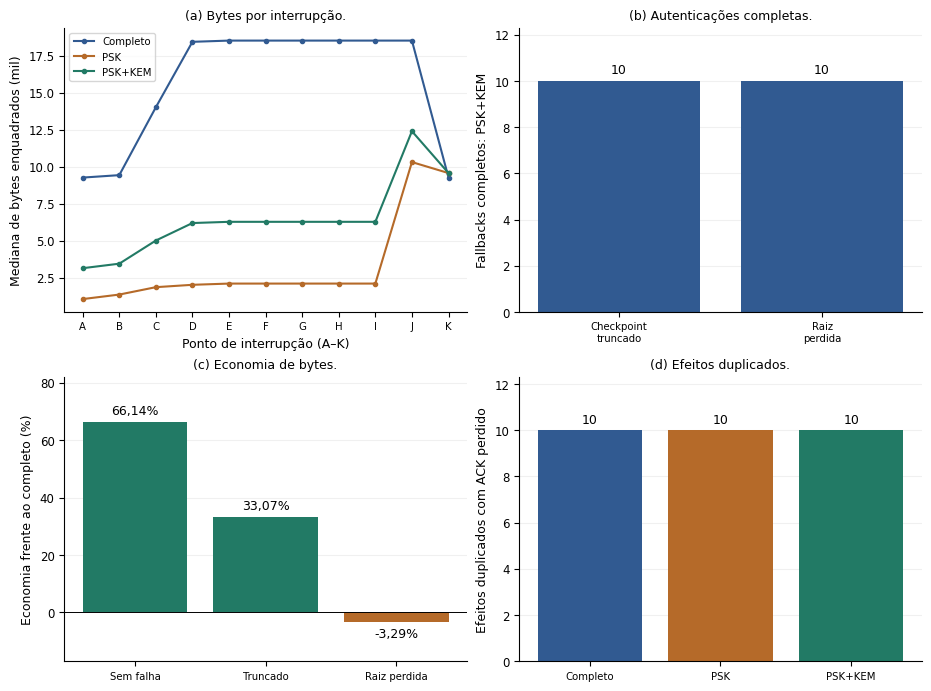

In [8]:
# (d) Duplicações provocadas pela confirmação perdida.
duplicados = interrupcoes.query("scenario == 'lost_reading_ack'").groupby("policy")["application_duplicates"].sum().reindex(modos_prototipo)
barras = eixos5[1, 1].bar(["Completo", "PSK", "PSK+KEM"], duplicados, color=cores)
eixos5[1, 1].bar_label(barras, fmt="%g", padding=3)
eixos5[1, 1].set(title="(d) Efeitos duplicados.", ylabel="Efeitos duplicados com ACK perdido", ylim=(0, max(duplicados.max() * 1.23, 1)))
for ax in eixos5.flat:
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)
for formato in ("png", "pdf", "svg"):
    fig5.savefig(pasta_prototipo / f"figura_5_interrupcoes.{formato}", dpi=300)
display(fig5)
plt.close(fig5);


### Executando a continuidade TLS

Cada execução envia nove leituras de 31 bytes. Variamos reinícios e confirmações perdidas em 0%, 25% e 100% das oito leituras elegíveis, com e sem deduplicação. São 1.620 execuções sem perda de pacotes e 180 com perdas de 1% e 5%.

O controlador conserva a leitura pendente por até três tentativas. A confirmação é suprimida após o registro persistente do efeito.


In [9]:
rede.recovery.run_continuity(source="iot_1", destination="server_1", blocks=10, readings=9)
rede.recovery.analyze_continuity()


*** sta1-wlan0: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
*** ap1-wlan1: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
(2ms delay 0.00000% loss) (2ms delay 0.00000% loss) 

{"completed": 1, "planned": 1620, "case": "l0_b0_r1_a0_pqc_resume_volatile_d0", "status": "PASS"}
{"completed": 2, "planned": 1620, "case": "l0_b0_r1_a0_classical_full_d1", "status": "PASS"}
{"completed": 3, "planned": 1620, "case": "l0_b0_r0_a0_hybrid_resume_preserved_d1", "status": "PASS"}
{"completed": 4, "planned": 1620, "case": "l0_b0_r0.25_a0.25_classical_resume_volatile_d0", "status": "PASS"}
{"completed": 5, "planned": 1620, "case": "l0_b0_r0.25_a0.25_classical_resume_preserved_d0", "status": "PASS"}
{"completed": 6, "planned": 1620, "case": "l0_b0_r0_a0.25_classical_resume_volatile_d1", "status": "PASS"}
{"completed": 7, "planned": 1620, "case": "l0_b0_r0_a0.25_pqc_resume_volatile_d1", "status": "PASS"}
{"completed": 8, "planned": 1620, "case": "l0_b0_r1_a0.25_hybrid_resume_volatile_d1", "status": "PASS"}
{"completed": 9, "planned": 1620, "case": "l0_b0_r1_a0_classical_resume_preserved_d0", "status": "PASS"}
{"completed": 10, "planned": 1620, "case": "l0_b0_r0.25_a0.25_hybrid_

*** Stopping 1 controllers
c0 
*** Stopping 3 links
...
*** Stopping switches/access points
ap1 
*** Stopping nodes
h1 sta1 

*** Removing WiFi module and Configurations
*** Killing mac80211_hwsim

*** Done
*** sta1-wlan0: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
*** ap1-wlan1: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
(2ms delay 0.00000% loss) (2ms delay 0.00000% loss) 

{"completed": 163, "planned": 1620, "case": "l0_b1_r0.25_a0_pqc_resume_preserved_d1", "status": "PASS"}
{"completed": 164, "planned": 1620, "case": "l0_b1_r1_a0.25_hybrid_resume_volatile_d1", "status": "PASS"}
{"completed": 165, "planned": 1620, "case": "l0_b1_r0.25_a1_hybrid_resume_preserved_d0", "status": "PASS"}
{"completed": 166, "planned": 1620, "case": "l0_b1_r0_a0_hybrid_resume_preserved_d1", "status": "PASS"}
{"completed": 167, "planned": 1620, "case": "l0_b1_r0.25_a1_pqc_resume_preserved_d1", "status": "PASS"}
{"completed": 168, "planned": 1620, "case": "l0_b1_r1_a0.25_classical_resume_preserved_d1", "status": "PASS"}
{"completed": 169, "planned": 1620, "case": "l0_b1_r0_a0.25_classical_full_d0", "status": "PASS"}
{"completed": 170, "planned": 1620, "case": "l0_b1_r1_a0_hybrid_resume_volatile_d0", "status": "PASS"}
{"completed": 171, "planned": 1620, "case": "l0_b1_r0.25_a0_classical_full_d1", "status": "PASS"}
{"completed": 172, "planned": 1620, "case": "l0_b1_r0.25_a0.25_hyb

*** Stopping 1 controllers
c0 
*** Stopping 3 links
...
*** Stopping switches/access points
ap1 
*** Stopping nodes
h1 sta1 

*** Removing WiFi module and Configurations
*** Killing mac80211_hwsim

*** Done
*** sta1-wlan0: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
*** ap1-wlan1: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
(2ms delay 0.00000% loss) (2ms delay 0.00000% loss) 

{"completed": 325, "planned": 1620, "case": "l0_b2_r0_a0_classical_full_d1", "status": "PASS"}
{"completed": 326, "planned": 1620, "case": "l0_b2_r0.25_a0.25_classical_resume_preserved_d0", "status": "PASS"}
{"completed": 327, "planned": 1620, "case": "l0_b2_r1_a0_pqc_resume_preserved_d0", "status": "PASS"}
{"completed": 328, "planned": 1620, "case": "l0_b2_r0.25_a1_pqc_resume_volatile_d1", "status": "PASS"}
{"completed": 329, "planned": 1620, "case": "l0_b2_r0.25_a0_hybrid_full_d0", "status": "PASS"}
{"completed": 330, "planned": 1620, "case": "l0_b2_r1_a1_pqc_resume_preserved_d0", "status": "PASS"}
{"completed": 331, "planned": 1620, "case": "l0_b2_r0_a0_classical_resume_volatile_d1", "status": "PASS"}
{"completed": 332, "planned": 1620, "case": "l0_b2_r0.25_a1_classical_resume_preserved_d1", "status": "PASS"}
{"completed": 333, "planned": 1620, "case": "l0_b2_r0.25_a0_pqc_resume_preserved_d1", "status": "PASS"}
{"completed": 334, "planned": 1620, "case": "l0_b2_r1_a0.25_hybrid_resum

... (55 outputs left out)

{"completed": 172, "planned": 180, "case": "l5_b9_r0.25_a0.25_pqc_resume_preserved_d1", "status": "PASS"}
{"completed": 173, "planned": 180, "case": "l5_b9_r0.25_a0.25_pqc_resume_volatile_d1", "status": "PASS"}
{"completed": 174, "planned": 180, "case": "l5_b9_r0.25_a0.25_hybrid_full_d1", "status": "PASS"}
{"completed": 175, "planned": 180, "case": "l5_b9_r0.25_a0.25_hybrid_resume_volatile_d1", "status": "PASS"}
{"completed": 176, "planned": 180, "case": "l5_b9_r0.25_a0.25_hybrid_resume_preserved_d1", "status": "PASS"}
{"completed": 177, "planned": 180, "case": "l5_b9_r0.25_a0.25_classical_resume_volatile_d1", "status": "PASS"}
{"completed": 178, "planned": 180, "case": "l5_b9_r0.25_a0.25_pqc_full_d1", "status": "PASS"}
{"completed": 179, "planned": 180, "case": "l5_b9_r0.25_a0.25_classical_full_d1", "status": "PASS"}
{"completed": 180, "planned": 180, "case": "l5_b9_r0.25_a0.25_classical_resume_preserved_d1", "status": "PASS"}


*** Stopping 1 controllers
c0 
*** Stopping 3 links
...
*** Stopping switches/access points
ap1 
*** Stopping nodes
h1 sta1 

*** Removing WiFi module and Configurations
*** Killing mac80211_hwsim

*** Done


{"status": "PASS", "cases": 180, "output": "/workspace/results/retomada/20261112T173322564183Z/loss"}
19:45:08 | Recuperação: continuity concluído
{
  "status": "PASS",
  "provenance": {
    "core": {
      "path": "/workspace/results/retomada/20261112T173322564183Z/core",
      "blocks": 10,
      "cases": 1620,
      "sha256": {
        "manifest.json": "4490948ad1b1e9ae47ff05e8f1f03e3c8d89fe98e5d54d4bc60ed8e431bc8dc9",
        "results.json": "a284b282fd2c1e407f45762997b3c7de9def8c2a72791cd91c1b16da0f6e3923"
      }
    },
    "loss": {
      "path": "/workspace/results/retomada/20261112T173322564183Z/loss",
      "blocks": 10,
      "cases": 180,
      "sha256": {
        "manifest.json": "80098dfda4d5e79b22876baa05a94be1c7917fbf53be059ed53b089adb4094c8",
        "results.json": "306eba5321683f6e9f4ea78c279a3392cf3b70d01bccaea262138842b2238986"
      }
    }
  },
  "analysis_python": "3.10.12 (main, Aug 31 2026, 10:18:17) [GCC 11.4.0]",
  "analysis_source_sha256": "1bfe6f49598b5db7

PosixPath('/workspace/results/retomada/20261112T173322564183Z/continuity_analysis')

### Consultando os custos de tráfego e tempo


In [10]:
rede.recovery.table("tls").round(2)


,phase,loss_pct,restart_fraction,ack_fraction,profile,deduplicate,treatment,blocks,median_ipv4_bytes_per_reading,median_mean_sequence_ms_per_reading,median_reading_recovery_ms,median_full_handshakes,median_resumed_handshakes,median_retry_full_handshakes,duplicate_effects,confirmed_readings,unconfirmed_readings,unplanned_unacknowledged
0,core,0,0.00,0.00,classical,False,full,10,4490.22,240.02,193.95,9.0,0.0,0.0,0,90,0,0
1,core,0,0.00,0.00,classical,False,resume_preserved,10,2681.89,235.64,191.46,1.0,8.0,0.0,0,90,0,0
2,core,0,0.00,0.00,classical,False,resume_volatile,10,2682.11,240.63,194.09,1.0,8.0,0.0,0,90,0,0
3,core,0,0.00,0.00,classical,True,full,10,4492.89,244.09,194.10,9.0,0.0,0.0,0,90,0,0
4,core,0,0.00,0.00,classical,True,resume_preserved,10,2682.11,239.63,193.28,1.0,8.0,0.0,0,90,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,loss,5,0.25,0.25,hybrid,True,resume_preserved,10,6098.72,605.09,408.95,1.0,10.0,0.0,0,90,0,0
176,loss,5,0.25,0.25,hybrid,True,resume_volatile,10,6687.89,549.92,418.23,3.0,8.0,0.0,0,90,0,0
177,loss,5,0.25,0.25,pqc,True,full,10,37418.56,576.73,446.71,11.0,0.0,2.0,0,90,0,0
178,loss,5,0.25,0.25,pqc,True,resume_preserved,10,12947.22,583.21,428.72,1.0,10.0,0.0,0,90,0,0


### Consultando as economias com ambas as falhas em 100%


In [11]:
rede.recovery.table("tls_comparisons").query(
    "phase == 'core' and profile == 'pqc' and restart_fraction == 1 and ack_fraction == 1 and deduplicate"
).round(2)


,phase,loss_pct,restart_fraction,ack_fraction,profile,deduplicate,treatment,blocks,median_paired_saving_pct,bootstrap95_low,bootstrap95_high,all_deliveries_complete,median_paired_time_delta_ms,time95_low,time95_high
106,core,0,1.0,1.0,pqc,True,resume_volatile,10,-14.24,-14.28,-14.23,True,21.70,5.39,38.85
107,core,0,1.0,1.0,pqc,True,resume_preserved,10,67.88,67.85,67.89,True,-16.73,-20.40,4.90


### Executando a comparação das cadeias de certificados

Enviamos folha e raiz ou apenas folha, mantendo a raiz confiável. São nove leituras de 31 bytes por execução, com ambas as falhas em 0%, 25% ou 100%, deduplicação ativa e perda de pacotes de 0%.


In [12]:
rede.recovery.run_chains(source="iot_1", destination="server_1", blocks=10)


*** sta1-wlan0: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
*** ap1-wlan1: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
(2ms delay 0.00000% loss) (2ms delay 0.00000% loss) 

{"completed": 1, "planned": 540, "case": "b0_r0.25_a0.25_pqc_resume_preserved_root1"}
{"completed": 2, "planned": 540, "case": "b0_r1_a1_pqc_resume_volatile_root1"}
{"completed": 3, "planned": 540, "case": "b0_r1_a1_hybrid_resume_volatile_root1"}
{"completed": 4, "planned": 540, "case": "b0_r0.25_a0.25_pqc_resume_preserved_root0"}
{"completed": 5, "planned": 540, "case": "b0_r1_a1_pqc_resume_preserved_root0"}
{"completed": 6, "planned": 540, "case": "b0_r0_a0_pqc_resume_volatile_root0"}
{"completed": 7, "planned": 540, "case": "b0_r0_a0_hybrid_resume_volatile_root1"}
{"completed": 8, "planned": 540, "case": "b0_r0_a0_classical_resume_preserved_root0"}
{"completed": 9, "planned": 540, "case": "b0_r0_a0_pqc_full_root0"}
{"completed": 10, "planned": 540, "case": "b0_r0.25_a0.25_pqc_resume_volatile_root0"}
{"completed": 11, "planned": 540, "case": "b0_r1_a1_classical_full_root1"}
{"completed": 12, "planned": 540, "case": "b0_r1_a1_classical_resume_preserved_root0"}
{"completed": 13, "plann

*** Stopping 1 controllers
c0 
*** Stopping 3 links
...
*** Stopping switches/access points
ap1 
*** Stopping nodes
h1 sta1 

*** Removing WiFi module and Configurations
*** Killing mac80211_hwsim

*** Done
*** sta1-wlan0: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
*** ap1-wlan1: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
(2ms delay 0.00000% loss) (2ms delay 0.00000% loss) 

{"completed": 55, "planned": 540, "case": "b1_r0_a0_classical_resume_volatile_root1"}
{"completed": 56, "planned": 540, "case": "b1_r0_a0_pqc_full_root0"}
{"completed": 57, "planned": 540, "case": "b1_r0.25_a0.25_pqc_full_root1"}
{"completed": 58, "planned": 540, "case": "b1_r0.25_a0.25_pqc_resume_volatile_root1"}
{"completed": 59, "planned": 540, "case": "b1_r0_a0_classical_full_root1"}
{"completed": 60, "planned": 540, "case": "b1_r0.25_a0.25_hybrid_resume_volatile_root0"}
{"completed": 61, "planned": 540, "case": "b1_r1_a1_classical_resume_preserved_root1"}
{"completed": 62, "planned": 540, "case": "b1_r0.25_a0.25_hybrid_resume_volatile_root1"}
{"completed": 63, "planned": 540, "case": "b1_r1_a1_hybrid_resume_volatile_root0"}
{"completed": 64, "planned": 540, "case": "b1_r0_a0_pqc_resume_volatile_root0"}
{"completed": 65, "planned": 540, "case": "b1_r0_a0_hybrid_resume_volatile_root0"}
{"completed": 66, "planned": 540, "case": "b1_r0_a0_hybrid_full_root0"}
{"completed": 67, "planned

*** Stopping 1 controllers
c0 
*** Stopping 3 links
...
*** Stopping switches/access points
ap1 
*** Stopping nodes
h1 sta1 

*** Removing WiFi module and Configurations
*** Killing mac80211_hwsim

*** Done
*** sta1-wlan0: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
*** ap1-wlan1: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
(2ms delay 0.00000% loss) (2ms delay 0.00000% loss) 

{"completed": 109, "planned": 540, "case": "b2_r0_a0_pqc_resume_preserved_root1"}
{"completed": 110, "planned": 540, "case": "b2_r0_a0_classical_resume_preserved_root0"}
{"completed": 111, "planned": 540, "case": "b2_r1_a1_classical_resume_volatile_root0"}
{"completed": 112, "planned": 540, "case": "b2_r0.25_a0.25_classical_resume_volatile_root1"}
{"completed": 113, "planned": 540, "case": "b2_r0_a0_classical_resume_volatile_root0"}
{"completed": 114, "planned": 540, "case": "b2_r0.25_a0.25_classical_resume_preserved_root0"}
{"completed": 115, "planned": 540, "case": "b2_r0_a0_hybrid_resume_volatile_root1"}
{"completed": 116, "planned": 540, "case": "b2_r1_a1_pqc_resume_preserved_root0"}
{"completed": 117, "planned": 540, "case": "b2_r0.25_a0.25_pqc_resume_volatile_root0"}
{"completed": 118, "planned": 540, "case": "b2_r0.25_a0.25_hybrid_resume_volatile_root0"}
{"completed": 119, "planned": 540, "case": "b2_r0_a0_hybrid_resume_volatile_root0"}
{"completed": 120, "planned": 540, "case":

... (13 outputs left out)

{"completed": 487, "planned": 540, "case": "b9_r0_a0_classical_resume_volatile_root1"}
{"completed": 488, "planned": 540, "case": "b9_r1_a1_classical_resume_preserved_root1"}
{"completed": 489, "planned": 540, "case": "b9_r1_a1_pqc_resume_preserved_root1"}
{"completed": 490, "planned": 540, "case": "b9_r0.25_a0.25_hybrid_resume_preserved_root1"}
{"completed": 491, "planned": 540, "case": "b9_r0.25_a0.25_classical_resume_volatile_root0"}
{"completed": 492, "planned": 540, "case": "b9_r1_a1_hybrid_resume_preserved_root0"}
{"completed": 493, "planned": 540, "case": "b9_r0_a0_hybrid_full_root1"}
{"completed": 494, "planned": 540, "case": "b9_r1_a1_classical_resume_volatile_root1"}
{"completed": 495, "planned": 540, "case": "b9_r0.25_a0.25_classical_resume_preserved_root1"}
{"completed": 496, "planned": 540, "case": "b9_r0.25_a0.25_pqc_resume_preserved_root0"}
{"completed": 497, "planned": 540, "case": "b9_r1_a1_classical_full_root1"}
{"completed": 498, "planned": 540, "case": "b9_r0.25_a0.

*** Stopping 1 controllers
c0 
*** Stopping 3 links
...
*** Stopping switches/access points
ap1 
*** Stopping nodes
h1 sta1 

*** Removing WiFi module and Configurations
*** Killing mac80211_hwsim

*** Done


{"status": "PASS", "cases": 540}
20:22:53 | Recuperação: chains concluído


PosixPath('/workspace/results/retomada/20261112T173322564183Z/chains')

### Executando a comparação de leituras por conexão

Mantemos 100 leituras de 512 bytes, em um processo cliente, com limites de 1, 10 e 100 leituras por conexão. O primeiro handshake completo integra o custo.

Na recuperação, o servidor reinicia antes da 51ª leitura e suprime sua primeira confirmação após o registro persistente. As duas matrizes têm 540 execuções cada.


In [13]:
rede.recovery.run_amortization(source="iot_1", destination="server_1", blocks=10)


*** sta1-wlan0: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
*** ap1-wlan1: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
(2ms delay 0.00000% loss) (2ms delay 0.00000% loss) 

{"completed": 1, "planned": 540, "case": "b0_classical_full_n10_recovery1"}
{"completed": 2, "planned": 540, "case": "b0_classical_resume_preserved_n1_recovery0"}
{"completed": 3, "planned": 540, "case": "b0_hybrid_resume_preserved_n1_recovery1"}
{"completed": 4, "planned": 540, "case": "b0_hybrid_resume_preserved_n10_recovery1"}
{"completed": 5, "planned": 540, "case": "b0_classical_full_n1_recovery1"}
{"completed": 6, "planned": 540, "case": "b0_hybrid_resume_volatile_n10_recovery0"}
{"completed": 7, "planned": 540, "case": "b0_pqc_full_n100_recovery1"}
{"completed": 8, "planned": 540, "case": "b0_hybrid_resume_volatile_n10_recovery1"}
{"completed": 9, "planned": 540, "case": "b0_pqc_resume_volatile_n10_recovery0"}
{"completed": 10, "planned": 540, "case": "b0_classical_resume_preserved_n10_recovery0"}
{"completed": 11, "planned": 540, "case": "b0_classical_resume_volatile_n10_recovery0"}
{"completed": 12, "planned": 540, "case": "b0_classical_resume_volatile_n1_recovery0"}
{"complet

*** Stopping 1 controllers
c0 
*** Stopping 3 links
...
*** Stopping switches/access points
ap1 
*** Stopping nodes
h1 sta1 

*** Removing WiFi module and Configurations
*** Killing mac80211_hwsim

*** Done
*** sta1-wlan0: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
*** ap1-wlan1: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
(2ms delay 0.00000% loss) (2ms delay 0.00000% loss) 

{"completed": 55, "planned": 540, "case": "b1_classical_resume_preserved_n100_recovery1"}
{"completed": 56, "planned": 540, "case": "b1_classical_full_n100_recovery0"}
{"completed": 57, "planned": 540, "case": "b1_pqc_full_n10_recovery0"}
{"completed": 58, "planned": 540, "case": "b1_hybrid_full_n10_recovery1"}
{"completed": 59, "planned": 540, "case": "b1_classical_full_n10_recovery0"}
{"completed": 60, "planned": 540, "case": "b1_hybrid_full_n100_recovery0"}
{"completed": 61, "planned": 540, "case": "b1_classical_resume_volatile_n10_recovery1"}
{"completed": 62, "planned": 540, "case": "b1_pqc_resume_preserved_n100_recovery0"}
{"completed": 63, "planned": 540, "case": "b1_hybrid_resume_preserved_n10_recovery0"}
{"completed": 64, "planned": 540, "case": "b1_hybrid_resume_volatile_n10_recovery0"}
{"completed": 65, "planned": 540, "case": "b1_classical_resume_volatile_n10_recovery0"}
{"completed": 66, "planned": 540, "case": "b1_classical_full_n1_recovery1"}
{"completed": 67, "planned":

*** Stopping 1 controllers
c0 
*** Stopping 3 links
...
*** Stopping switches/access points
ap1 
*** Stopping nodes
h1 sta1 

*** Removing WiFi module and Configurations
*** Killing mac80211_hwsim

*** Done
*** sta1-wlan0: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
*** ap1-wlan1: requested 200.00m -> effective 200.00m (delta +0.00m) using tx power 9 dBm
(2ms delay 0.00000% loss) (2ms delay 0.00000% loss) 

{"completed": 109, "planned": 540, "case": "b2_classical_full_n1_recovery1"}
{"completed": 110, "planned": 540, "case": "b2_hybrid_resume_preserved_n10_recovery1"}
{"completed": 111, "planned": 540, "case": "b2_hybrid_resume_preserved_n10_recovery0"}
{"completed": 112, "planned": 540, "case": "b2_classical_resume_preserved_n100_recovery1"}
{"completed": 113, "planned": 540, "case": "b2_pqc_resume_volatile_n10_recovery0"}
{"completed": 114, "planned": 540, "case": "b2_hybrid_resume_volatile_n100_recovery0"}
{"completed": 115, "planned": 540, "case": "b2_classical_resume_preserved_n100_recovery0"}
{"completed": 116, "planned": 540, "case": "b2_pqc_resume_preserved_n100_recovery0"}
{"completed": 117, "planned": 540, "case": "b2_hybrid_full_n10_recovery1"}
{"completed": 118, "planned": 540, "case": "b2_pqc_resume_volatile_n10_recovery1"}
{"completed": 119, "planned": 540, "case": "b2_classical_resume_preserved_n1_recovery0"}
{"completed": 120, "planned": 540, "case": "b2_pqc_full_n100_reco

... (13 outputs left out)

{"completed": 487, "planned": 540, "case": "b9_classical_resume_volatile_n10_recovery0"}
{"completed": 488, "planned": 540, "case": "b9_hybrid_full_n1_recovery1"}
{"completed": 489, "planned": 540, "case": "b9_classical_resume_volatile_n100_recovery1"}
{"completed": 490, "planned": 540, "case": "b9_hybrid_resume_volatile_n100_recovery1"}
{"completed": 491, "planned": 540, "case": "b9_pqc_full_n1_recovery1"}
{"completed": 492, "planned": 540, "case": "b9_classical_full_n100_recovery0"}
{"completed": 493, "planned": 540, "case": "b9_classical_resume_preserved_n100_recovery1"}
{"completed": 494, "planned": 540, "case": "b9_classical_resume_volatile_n10_recovery1"}
{"completed": 495, "planned": 540, "case": "b9_classical_resume_volatile_n100_recovery0"}
{"completed": 496, "planned": 540, "case": "b9_hybrid_resume_volatile_n1_recovery0"}
{"completed": 497, "planned": 540, "case": "b9_classical_full_n10_recovery0"}
{"completed": 498, "planned": 540, "case": "b9_hybrid_resume_preserved_n1_rec

*** Stopping 1 controllers
c0 
*** Stopping 3 links
...
*** Stopping switches/access points
ap1 
*** Stopping nodes
h1 sta1 

*** Removing WiFi module and Configurations
*** Killing mac80211_hwsim

*** Done


{"status": "PASS", "cases": 540}
20:48:56 | Recuperação: amortization concluído


PosixPath('/workspace/results/retomada/20261112T173322564183Z/amortization')

### Verificando tickets, persistência e identidade do dispositivo


In [14]:
rede.recovery.run_security()


{"status": "PASS", "cases": 12, "valid_other_identity_rejected": true}
{"status": "PASS", "ledger_checks": 100, "checkpoint_encryptions": 1000}
{"completed": 1, "profile": "classical", "boundary": "after_reading_insert", "termination": "sigterm_cleanup"}
{"completed": 2, "profile": "classical", "boundary": "after_reading_insert", "termination": "sigkill"}
{"completed": 3, "profile": "classical", "boundary": "after_effect_insert", "termination": "sigterm_cleanup"}
{"completed": 4, "profile": "classical", "boundary": "after_effect_insert", "termination": "sigkill"}
{"completed": 5, "profile": "classical", "boundary": "before_commit", "termination": "sigterm_cleanup"}
{"completed": 6, "profile": "classical", "boundary": "before_commit", "termination": "sigkill"}
{"completed": 7, "profile": "classical", "boundary": "after_commit", "termination": "sigterm_cleanup"}
{"completed": 8, "profile": "classical", "boundary": "after_commit", "termination": "sigkill"}
{"completed": 9, "profile": "cla

{'identity_tickets': '/workspace/results/retomada/20261112T173322564183Z/identity_tickets',
 'persistence': '/workspace/results/retomada/20261112T173322564183Z/persistence',
 'tls_persistence': '/workspace/results/retomada/20261112T173322564183Z/tls_persistence',
 'continuity_security': '/workspace/results/retomada/20261112T173322564183Z/continuity_security'}

### Analisando as medições dos experimentos

Calculamos medianas e economias frente ao completo do mesmo perfil e bloco. Os intervalos de 95% usam 10.000 reamostragens bootstrap e são exploratórios. Valores negativos de economia indicam aumento de tráfego.


In [15]:
rede.recovery.analyze_context()


{
  "status": "PASS",
  "chain_cases": 540,
  "chain_readings": 4860,
  "chain_confirmed": 4860,
  "chain_duplicate_effects": 0,
  "bootstrap_samples": 10000,
  "bootstrap_seed": 20261106,
  "inference": "exploratory per condition; block is repetition",
  "inputs": {
    "/workspace/results/retomada/20261112T173322564183Z/chains/results.json": "2b975af28e81bb2558b95e6794c2d1abee4e9d6ef3e0f666a98f45e4c420bb7c",
    "/workspace/results/retomada/20261112T173322564183Z/amortization/results.json": "b52b67c09e509f20aa5d32f4cf9d48efa92138caab1eeff5aa94035391d49594"
  },
  "analyzer_sha256": "3dfdab1191d48440362de6f29c57ef615794810991728a9f677ae98256d2456e",
  "amortization_cases": 540,
  "amortization_readings": 54000,
  "amortization_confirmed": 54000,
  "amortization_duplicate_effects": 0
}
{
  "status": "PASS",
  "kind": "chains",
  "cases": 540,
  "confirmed_readings": 4860,
  "clienthellos_verified_against_capture": 6660,
  "emitted_ticket_lengths_verified": 3678,
  "checks": [
    "exac

PosixPath('/workspace/results/retomada/20261112T173322564183Z/context_analysis')

### Consultando o custo das cadeias de certificados


In [16]:
rede.recovery.table("chains").query("restart_fraction == 1 and ack_fraction == 1").round(2)


,restart_fraction,ack_fraction,profile,include_root,treatment,blocks,executions,confirmed_readings,unconfirmed_readings,median_ipv4_total_bytes,median_ipv4_bytes_per_confirmed_reading,median_ms_per_reading,median_full_handshakes,median_resumed_handshakes,duplicate_effects
36,1.0,1.0,classical,0,full,10,10,90,0,60145.0,6682.78,654.65,17.0,0.0,0
37,1.0,1.0,classical,0,resume_preserved,10,10,90,0,40547.0,4505.22,647.18,1.0,16.0,0
38,1.0,1.0,classical,0,resume_volatile,10,10,90,0,70565.5,7840.61,651.52,17.0,0.0,0
39,1.0,1.0,classical,1,full,10,10,90,0,73911.0,8212.33,651.71,17.0,0.0,0
40,1.0,1.0,classical,1,resume_preserved,10,10,90,0,41331.5,4592.39,647.89,1.0,16.0,0
41,1.0,1.0,classical,1,resume_volatile,10,10,90,0,85247.5,9471.94,657.19,17.0,0.0,0
42,1.0,1.0,hybrid,0,full,10,10,90,0,98224.5,10913.83,657.10,17.0,0.0,0
43,1.0,1.0,hybrid,0,resume_preserved,10,10,90,0,80646.0,8960.67,651.62,1.0,16.0,0
44,1.0,1.0,hybrid,0,resume_volatile,10,10,90,0,111119.0,12346.56,656.19,17.0,0.0,0
45,1.0,1.0,hybrid,1,full,10,10,90,0,112443.0,12493.67,654.43,17.0,0.0,0


### Consultando a economia com a perda e a preservação do contexto


In [17]:
rede.recovery.table("chain_comparisons").query("restart_fraction == 1 and ack_fraction == 1").round(2)


,restart_fraction,ack_fraction,profile,include_root,treatment,blocks,median_savings_pct,savings_ci_low,savings_ci_high,median_bytes_difference_per_reading,bytes_difference_ci_low,bytes_difference_ci_high,median_ms_difference_per_reading,ms_ci_low,ms_ci_high
24,1.0,1.0,classical,0,resume_volatile,10,-17.31,-17.32,-17.27,1156.83,1154.83,1157.67,-1.41,-5.82,8.12
25,1.0,1.0,classical,0,resume_preserved,10,32.58,32.57,32.63,-2177.50,-2182.17,-2176.00,-0.21,-12.32,3.86
26,1.0,1.0,classical,1,resume_volatile,10,-15.30,-15.41,-15.13,1255.89,1244.22,1265.22,7.99,-1.28,13.14
27,1.0,1.0,classical,1,resume_preserved,10,44.08,44.05,44.15,-3619.89,-3631.22,-3615.89,-1.88,-8.58,4.48
28,1.0,1.0,hybrid,0,resume_volatile,10,-13.16,-13.30,-13.05,1435.72,1424.78,1450.78,-0.59,-11.13,11.81
29,1.0,1.0,hybrid,0,resume_preserved,10,17.86,17.84,17.96,-1948.89,-1962.22,-1945.39,-1.82,-13.48,3.28
30,1.0,1.0,hybrid,1,resume_volatile,10,-11.49,-11.63,-11.39,1434.17,1423.44,1452.22,7.45,4.64,23.43
31,1.0,1.0,hybrid,1,resume_preserved,10,27.53,27.47,27.57,-3440.06,-3445.78,-3429.22,-5.96,-9.19,16.57
32,1.0,1.0,pqc,0,resume_volatile,10,-19.80,-19.82,-19.78,8187.11,8177.33,8195.78,11.58,2.43,16.75
33,1.0,1.0,pqc,0,resume_preserved,10,57.70,57.67,57.72,-23852.89,-23864.44,-23841.33,-9.92,-15.51,-0.28


### Consultando os custos e as economias por quantidade de leituras na conexão


In [18]:
rede.recovery.table("amortization").query("profile == 'pqc'").round(2)


,recovery,batch_size,profile,treatment,blocks,executions,confirmed_readings,unconfirmed_readings,median_ipv4_total_bytes,median_ipv4_bytes_per_confirmed_reading,median_ms_per_reading,median_full_handshakes,median_resumed_handshakes,duplicate_effects
6,False,1,pqc,full,10,10,1000,0,2276586.0,22765.86,47.41,100.0,0.0,0
7,False,1,pqc,resume_preserved,10,10,1000,0,948379.0,9483.79,40.32,1.0,99.0,0
8,False,1,pqc,resume_volatile,10,10,1000,0,948431.0,9484.31,40.29,1.0,99.0,0
15,False,10,pqc,full,10,10,1000,0,325100.0,3251.00,17.67,10.0,0.0,0
16,False,10,pqc,resume_preserved,10,10,1000,0,204439.0,2044.39,16.85,1.0,9.0,0
17,False,10,pqc,resume_volatile,10,10,1000,0,204413.0,2044.13,17.11,1.0,9.0,0
24,False,100,pqc,full,10,10,1000,0,129980.0,1299.80,14.48,1.0,0.0,0
25,False,100,pqc,resume_preserved,10,10,1000,0,129980.0,1299.80,14.21,1.0,0.0,0
26,False,100,pqc,resume_volatile,10,10,1000,0,129980.0,1299.80,14.51,1.0,0.0,0
33,True,1,pqc,full,10,10,1000,0,2298822.0,22988.22,50.92,101.0,0.0,0


In [19]:
rede.recovery.table("amortization_comparisons").query("profile == 'pqc'").round(2)


,recovery,batch_size,profile,treatment,blocks,median_savings_pct,savings_ci_low,savings_ci_high,median_bytes_difference_per_reading,bytes_difference_ci_low,bytes_difference_ci_high,median_ms_difference_per_reading,ms_ci_low,ms_ci_high
4,False,1,pqc,resume_volatile,10,58.34,58.33,58.36,-13280.51,-13286.23,-13278.43,-7.11,-7.46,-6.65
5,False,1,pqc,resume_preserved,10,58.34,58.32,58.35,-13282.33,-13284.15,-13277.39,-6.81,-7.52,-6.17
10,False,10,pqc,resume_volatile,10,37.13,37.10,37.14,-1207.13,-1207.65,-1206.09,-0.23,-1.35,0.53
11,False,10,pqc,resume_preserved,10,37.12,37.12,37.14,-1206.61,-1207.65,-1206.61,-0.78,-1.35,-0.45
16,False,100,pqc,resume_volatile,10,0.00,-0.02,0.00,0.00,0.00,0.26,0.18,-0.56,0.38
17,False,100,pqc,resume_preserved,10,0.00,-0.02,0.00,0.00,0.00,0.26,-0.27,-0.52,0.28
22,True,1,pqc,resume_volatile,10,56.77,56.76,56.78,-13049.78,-13054.46,-13047.96,-6.35,-7.08,-5.76
23,True,1,pqc,resume_preserved,10,58.35,58.33,58.36,-13413.22,-13417.12,-13410.88,-7.16,-7.88,-6.40
28,True,10,pqc,resume_volatile,10,28.23,28.21,28.24,-981.08,-981.34,-980.30,-0.73,-1.23,-0.19
29,True,10,pqc,resume_preserved,10,38.58,38.57,38.59,-1340.62,-1340.88,-1340.10,-0.90,-1.03,-0.65


### Figura 6 — Cadeias, tickets e leituras por conexão

Lemos as tabelas da campanha atual. Os painéis usam as mesmas condições, cores e legendas do artigo; os intervalos são os calculados pela análise dos experimentos.


In [20]:
custos_cadeias = rede.recovery.table("chains")
economias_cadeias = rede.recovery.table("chain_comparisons")
custos_conexoes = rede.recovery.table("amortization")
economias_conexoes = rede.recovery.table("amortization_comparisons")
perfis_tls = ["classical", "hybrid", "pqc"]
nomes_tls = ["X25519\nECDSA P-256", "X25519MLKEM768\nECDSA P-256", "X25519MLKEM768\nML-DSA-44"]
modos_tls = ["full", "resume_volatile", "resume_preserved"]
nomes_modos = ["Completo", "Perdido", "Preservado"]
x = np.arange(3)
fig6, eixos6 = plt.subplots(3, 2, figsize=(8.5, 10), layout="constrained")


#### (a) Custos sem transmitir a raiz


In [21]:
ax = eixos6[0, 0]
for j, (modo, nome, cor) in enumerate(zip(modos_tls, nomes_modos, cores)):
    valores = custos_cadeias.query("restart_fraction == 1 and ack_fraction == 1 and include_root == 0 and treatment == @modo").set_index("profile").loc[perfis_tls, "median_ipv4_bytes_per_confirmed_reading"]
    ax.bar(x + (j - 1) * 0.25, valores / 1000, 0.23, label=nome, color=cor)
ax.set_xticks(x, nomes_tls)
ax.set(title="(a) Custos sem transmitir a raiz.", ylabel="IPv4 por leitura (kB)")
ax.margins(y=0.25)
ax.set_ylim(bottom=0)
ax.legend(ncol=3, fontsize=7);


#### (b) Efeito da cadeia na economia


In [22]:
ax = eixos6[0, 1]
series_cadeias = [(1, "resume_volatile", cores[1], "//"), (0, "resume_volatile", cores[1], ""),
                  (1, "resume_preserved", cores[2], "//"), (0, "resume_preserved", cores[2], "")]
for j, (raiz, modo, cor, hachura) in enumerate(series_cadeias):
    dados = economias_cadeias.query("restart_fraction == 1 and ack_fraction == 1 and include_root == @raiz and treatment == @modo").set_index("profile").loc[perfis_tls]
    erro = [dados["median_savings_pct"] - dados["savings_ci_low"], dados["savings_ci_high"] - dados["median_savings_pct"]]
    ax.bar(x + (j - 1.5) * 0.19, dados["median_savings_pct"], 0.18, color=cor, hatch=hachura, edgecolor="white", yerr=erro, capsize=1.5)
ax.set_xticks(x, nomes_tls)
ax.set(title="(b) Efeito da cadeia na economia.", ylabel="Economia frente ao completo (%)")
legenda = ax.legend(handles=[Patch(facecolor=cores[1], label="Perdido"), Patch(facecolor=cores[2], label="Preservado")], loc="upper left", ncol=2)
ax.add_artist(legenda)
ax.legend(handles=[Patch(facecolor="white", edgecolor="#555", hatch=h, label=n) for h, n in [("//", "Raiz enviada"), ("", "Raiz omitida")]], loc="lower left", ncol=2)
ax.axhline(0, color="black", linestyle="--", linewidth=0.7)
ax.margins(y=0.2);


#### (c) Certificado, estado da sessão e ticket


In [23]:
diagnostico = json.loads((rede.recovery.directory / "identity_tickets/results.json").read_text())
controles = TicketDiagnostics(diagnostico).matched_client_controls()
ax = eixos6[1, 0]
for j, (registro, nome, cor) in enumerate(zip(controles, ["Cliente ECDSA P-256", "Cliente ML-DSA-44"], cores)):
    conexao = registro["connections"][0]
    valores = [registro["certificates"]["client"]["der_bytes"], conexao["ticket_plaintext_session_der_bytes"], conexao["tickets_tx_bytes"][0]]
    barras = ax.bar(x + (j - 0.5) * 0.36, valores, 0.34, label=nome, color=cor)
    ax.bar_label(barras, labels=[f"{v:,}".replace(",", ".") for v in valores], padding=3, fontsize=7)
ax.set_xticks(x, ["Certificado\ndo cliente", "Estado\nda sessão", "Ticket"])
ax.set(title="(c) Certificado, estado e ticket.", ylabel="Tamanho (bytes)")
ax.margins(y=0.25)
ax.set_ylim(bottom=0)
ax.legend(fontsize=7);


#### (d) Custos por leitura sem falhas


In [24]:
ax = eixos6[1, 1]
for j, (modo, nome, cor) in enumerate(zip(modos_tls, nomes_modos, cores)):
    valores = custos_conexoes.query("profile == 'pqc' and recovery == False and treatment == @modo").set_index("batch_size").loc[[1, 10, 100], "median_ipv4_bytes_per_confirmed_reading"]
    ax.bar(x + (j - 1) * 0.25, valores / 1000, 0.23, label=nome, color=cor)
ax.set_xticks(x, ["1", "10", "100"])
ax.set(title="(d) Custos sem falhas.", xlabel="Limite de leituras por conexão", ylabel="IPv4 por leitura (kB)")
ax.margins(y=0.25)
ax.set_ylim(bottom=0)
ax.legend(ncol=3, fontsize=7);


#### (e) Economia na recuperação


In [25]:
ax = eixos6[2, 0]
for modo, nome, cor in zip(modos_tls[1:], nomes_modos[1:], cores[1:]):
    dados = economias_conexoes.query("profile == 'pqc' and recovery == True and treatment == @modo").set_index("batch_size").loc[[1, 10, 100]]
    erro = [dados["median_savings_pct"] - dados["savings_ci_low"], dados["savings_ci_high"] - dados["median_savings_pct"]]
    ax.errorbar(x, dados["median_savings_pct"], yerr=erro, color=cor, marker="o", capsize=2, label=nome)
ax.set_xticks(x, ["1", "10", "100"])
ax.set(title="(e) Economia na recuperação.", xlabel="Limite de leituras por conexão", ylabel="Economia frente ao completo (%)")
ax.axhline(0, color="black", linestyle="--", linewidth=0.7)
ax.margins(y=0.2)
ax.legend(ncol=2);


#### (f) Diferença de tempo com contexto preservado


In [26]:
ax = eixos6[2, 1]
for recuperacao, deslocamento, cor, marcador, nome in [(False, -0.07, cores[0], "s", "Sem falhas"), (True, 0.07, cores[2], "o", "Recuperação")]:
    dados = economias_conexoes.query("profile == 'pqc' and treatment == 'resume_preserved' and recovery == @recuperacao").set_index("batch_size").loc[[1, 10, 100]]
    erro = [dados["median_ms_difference_per_reading"] - dados["ms_ci_low"], dados["ms_ci_high"] - dados["median_ms_difference_per_reading"]]
    ax.errorbar(x + deslocamento, dados["median_ms_difference_per_reading"], yerr=erro, color=cor, fmt=marcador, capsize=3, label=nome)
ax.set_xticks(x, ["1", "10", "100"])
ax.set(title="(f) Tempo com contexto preservado.", xlabel="Limite de leituras por conexão", ylabel="Diferença de tempo (ms/leitura)")
ax.axhline(0, color="black", linestyle="--", linewidth=0.7)
ax.margins(y=0.2)
ax.legend(loc="lower right", ncol=2);


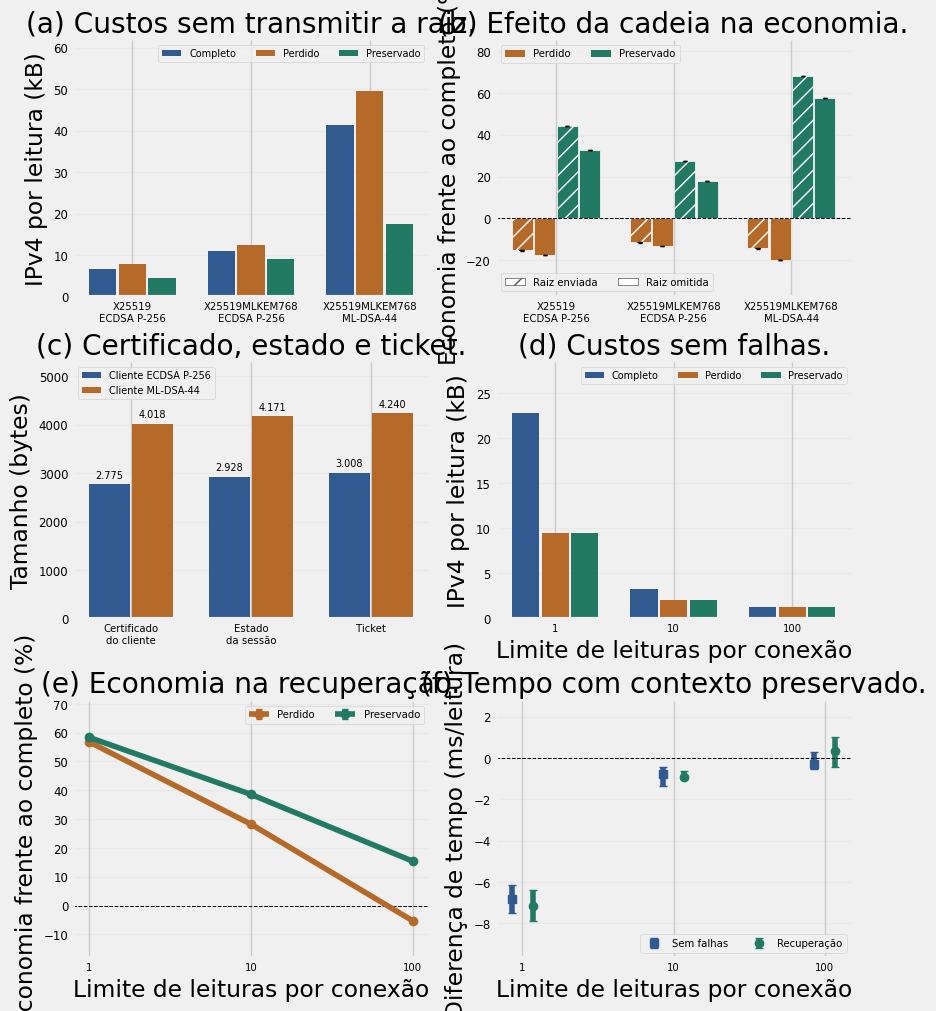

In [27]:
for ax in eixos6.flat:
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)
pasta_figuras = rede.recovery.directory / "figures"
pasta_figuras.mkdir(parents=True, exist_ok=True)
for formato in ("png", "pdf", "svg"):
    fig6.savefig(pasta_figuras / f"figura_6_contexto.{formato}", dpi=300)
display(fig6)
plt.close(fig6);


### Diretório dos resultados

As tabelas e os gráficos usam as medições da campanha iniciada acima. Reexecutar uma etapa substitui os resultados dessa etapa e descarta as análises e figuras que dependem dela. Os manifestos guardam topologia, parâmetros, versões e hashes do código.

Medimos tráfego IPv4 observado no servidor e tempo no host, com um sensor emulado. As falhas encerram processos; os efeitos avaliados são registros no banco.


In [28]:
rede.recovery.directory


PosixPath('/workspace/results/retomada/20261112T173322564183Z')